***Problem Statement:***

**In many industries, machine failures cause unexpected downtime, which leads to loss of time and productivity. It is difficult to manually estimate how long a failure will impact operations because it depends on multiple factors like the type of failure, machine condition, and time of occurrence.**
**This project aims to build a machine learning model that can predict the expected downtime (impact time in minutes) based on past failure data such as failure type, category, and machine performance. This helps in better planning, faster decision-making, and reducing operational losses.**

In [ ]:
#importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#reading dataset
df=pd.read_csv("D:\Practise\pratice\machine learning  Project\industrial_failure_dataset_global_lite.csv")
data=df.copy() #coping dataset 

FileNotFoundError: [Errno 2] No such file or directory: 'industrial_failure_dataset_global_lite.csv'

In [ ]:
df.shape

(6924, 15)

In [ ]:
df.isnull().sum()

event_id               5925
timestamp              5925
region                 5925
area                   5925
equipment              5925
failure_name           5925
failure_category       5925
severity               5925
root_cause             5925
root_cause_category    5925
impact_min             5925
mttr_min               5925
mtbf_hours             5926
year                   5925
month                  5925
dtype: int64

all these 5925 values are empty rows so i can drop these values

In [ ]:
data.columns

Index(['event_id', 'timestamp', 'region', 'area', 'equipment', 'failure_name',
       'failure_category', 'severity', 'root_cause', 'root_cause_category',
       'impact_min', 'mttr_min', 'mtbf_hours', 'year', 'month'],
      dtype='object')

In [ ]:
data['failure_name'].nunique() #total number of unique values in the failure_column 

141

In [ ]:
pd.get_dummies(data['failure_name']) #tried one hot encoding for failure_name but dropped because their are more columns

,atoramIENTO DE SACOS EN APLICADOR,2010 Fallo de equipo,2010 Fallo de equipo Falla cadena de cab,2010 Fallo de equipo Se daña varilla de,2010 Fallo de equipo curva rodillos 671,2010 Fallo de equipo falla de diafragma,AJUSTE APLICADOR DE SACOS,Acomodo de furgones en anden,Ajuste apliacdor de sacos,Ajuste aplicador de sacos,...,Turno/hrs No laborables,cambio de cpc30 50 kg a 42.60 kg,de mortero 25 kg a gris de 25 kg,lIMPIEZA INTERIOR ENVASADORA,lÍNEA LLENA Microparos,montacargas electricos en proceso de apr,personal en capacitación,personal en entrenamiento,solo 1 operador en línea por horario de,valvula de 11 cm
0,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6919,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6920,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6921,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6922,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
data.head()

,event_id,timestamp,region,area,equipment,failure_name,failure_category,severity,root_cause,root_cause_category,impact_min,mttr_min,mtbf_hours,year,month
0,E000001,01/01/2025 00:00,Global,Bagging & Palletizing,EQUIP_001,Turno/hrs No laborables,Idle/External,High,Turno/hrs No laborables,Idle/External,1440.00,1440.00,NaN,2025.0,1.0
1,E000002,02/01/2025 10:14,Global,Bagging & Palletizing,EQUIP_001,Ajuste apliacdor de sacos,Mechanical,High,Ajuste apliacdor de sacos,Mechanical,1.02,1.02,0.816667,2025.0,1.0
2,E000003,02/01/2025 12:22,Global,Bagging & Palletizing,EQUIP_001,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,High,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,1.02,1.02,0.150000,2025.0,1.0
3,E000004,02/01/2025 12:06,Global,Bagging & Palletizing,EQUIP_001,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,High,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,1.02,1.02,0.150000,2025.0,1.0
4,E000005,02/01/2025 12:13,Global,Bagging & Palletizing,EQUIP_001,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,High,Falta de bolsa en magaz/atoram. atoramie,Logistics/Organization,1.02,1.02,0.116667,2025.0,1.0


In [ ]:
data.columns

Index(['event_id', 'timestamp', 'region', 'area', 'equipment', 'failure_name',
       'failure_category', 'severity', 'root_cause', 'root_cause_category',
       'impact_min', 'mttr_min', 'mtbf_hours', 'year', 'month'],
      dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6924 entries, 0 to 6923
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   event_id             999 non-null    object 
 1   timestamp            999 non-null    object 
 2   region               999 non-null    object 
 3   area                 999 non-null    object 
 4   equipment            999 non-null    object 
 5   failure_name         999 non-null    object 
 6   failure_category     999 non-null    object 
 7   severity             999 non-null    object 
 8   root_cause           999 non-null    object 
 9   root_cause_category  999 non-null    object 
 10  impact_min           999 non-null    float64
 11  mttr_min             999 non-null    float64
 12  mtbf_hours           998 non-null    float64
 13  year                 999 non-null    float64
 14  month                999 non-null    float64
dtypes: float64(5), object(10)
memory usage

In [ ]:
data.describe()

,impact_min,mttr_min,mtbf_hours,year,month
count,999.000000,999.000000,998.000000,999.0,999.000000
mean,39.310210,39.310210,1.037943,2025.0,1.317317
std,161.328091,161.328091,2.688253,0.0,0.465665
min,0.000000,0.000000,0.000000,2025.0,1.000000
25%,1.020000,1.020000,0.116667,2025.0,1.000000
50%,1.980000,1.980000,0.316667,2025.0,1.000000
75%,4.980000,4.980000,0.733333,2025.0,2.000000
max,1440.000000,1440.000000,24.000000,2025.0,2.000000


In [ ]:
len(data)

6924

In [ ]:
#shape before removing empty columns
data.shape

(6924, 15)

In [ ]:
#removing empty columns
data.dropna().shape

(998, 15)

In [ ]:
#shape after removing empty columns
data.isnull().sum()

event_id               5925
timestamp              5925
region                 5925
area                   5925
equipment              5925
failure_name           5925
failure_category       5925
severity               5925
root_cause             5925
root_cause_category    5925
impact_min             5925
mttr_min               5925
mtbf_hours             5926
year                   5925
month                  5925
dtype: int64

In [ ]:
#remove all the empty rows and reshape the entire dataset
data=data.dropna(how='all')

In [ ]:
#updated shape after removing empty rows
data.shape

(999, 15)

In [ ]:
#number of null values after removing empty rows
data.isnull().sum()

event_id               0
timestamp              0
region                 0
area                   0
equipment              0
failure_name           0
failure_category       0
severity               0
root_cause             0
root_cause_category    0
impact_min             0
mttr_min               0
mtbf_hours             1
year                   0
month                  0
dtype: int64

In [ ]:
data.describe()

,impact_min,mttr_min,mtbf_hours,year,month
count,999.000000,999.000000,998.000000,999.0,999.000000
mean,39.310210,39.310210,1.037943,2025.0,1.317317
std,161.328091,161.328091,2.688253,0.0,0.465665
min,0.000000,0.000000,0.000000,2025.0,1.000000
25%,1.020000,1.020000,0.116667,2025.0,1.000000
50%,1.980000,1.980000,0.316667,2025.0,1.000000
75%,4.980000,4.980000,0.733333,2025.0,2.000000
max,1440.000000,1440.000000,24.000000,2025.0,2.000000


<Axes: xlabel='mtbf_hours'>

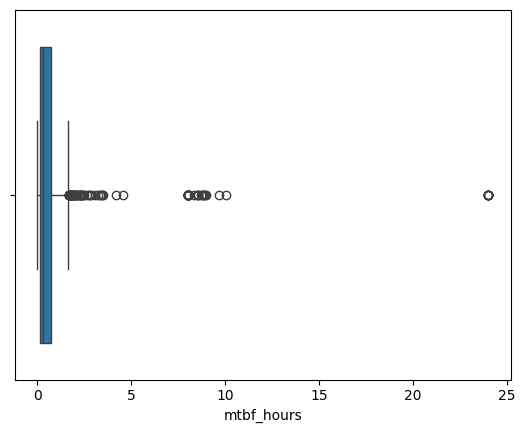

In [ ]:
sns.boxplot(x=data['mtbf_hours'])

In [ ]:
data[data['failure_category'] != data['root_cause_category']]

,event_id,timestamp,region,area,equipment,failure_name,failure_category,severity,root_cause,root_cause_category,impact_min,mttr_min,mtbf_hours,year,month


Both the failure_category and root_cause_category are same so i can drop any one of them

In [ ]:
#number of unique values in each column
for i in data.columns:
    print(i,":",data[i].nunique())

event_id : 999
timestamp : 965
region : 1
area : 1
equipment : 1
failure_name : 141
failure_category : 5
severity : 1
root_cause : 141
root_cause_category : 5
impact_min : 50
mttr_min : 50
mtbf_hours : 144
year : 1
month : 2


by this i can say that i can remove region,equipment,year, serverity and area columns

In [ ]:
data['area'].value_counts()

area
Bagging & Palletizing    999
Name: count, dtype: int64

In [ ]:
data['region'].value_counts()

region
Global    999
Name: count, dtype: int64

In [ ]:
data['equipment'].nunique()

1

In [ ]:
data['root_cause_category'].value_counts()

root_cause_category
Logistics/Organization    598
Mechanical                177
Electrical                144
Idle/External              66
Other                      14
Name: count, dtype: int64

Text(0, 0.5, 'count')

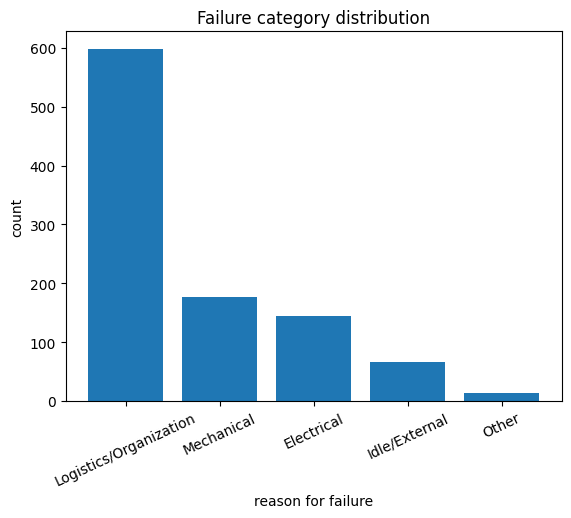

In [ ]:
failure=data['failure_category'].value_counts()
plt.bar(failure.index,failure.values)
plt.title("Failure category distribution")
plt.xlabel("reason for failure")
plt.xticks(rotation=25)
plt.ylabel("count")

Logistics/Organization is the main reason for most of the failures

Text(0.5, 1.0, 'Impact (Downtime) Distribution')

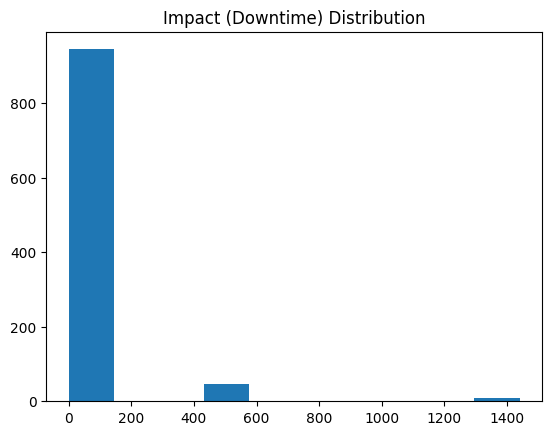

In [ ]:
plt.hist(data['impact_min'],bins=10)
plt.title("Impact (Downtime) Distribution")

In [ ]:
data['severity'].value_counts()

severity
High    999
Name: count, dtype: int64

data has only one value i.e high serverity values only so i can't predict serverity  

(array([944.,  47.,   0.,   0.,   8.]),
 array([   0.,  288.,  576.,  864., 1152., 1440.]),
 <BarContainer object of 5 artists>)

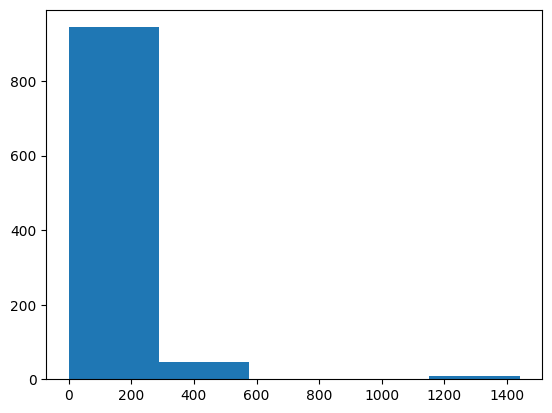

In [ ]:
plt.hist(data['mttr_min'],bins=5)

In [ ]:
data['mtbf_hours'].isnull().sum()

1

Text(0.5, 1.0, 'Avg downtime per Failure Type')

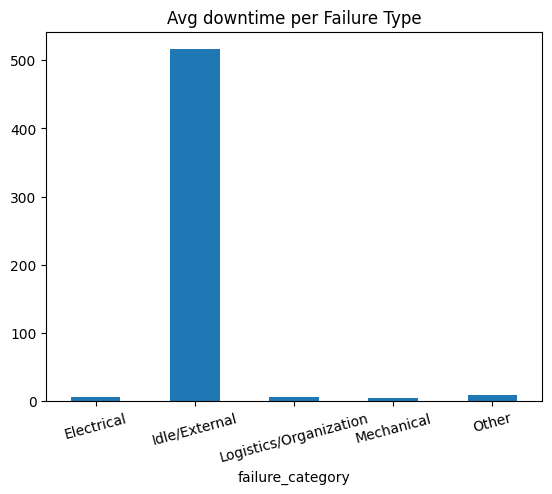

In [ ]:
data.groupby('failure_category')['impact_min'].mean().plot(kind='bar')
plt.xticks(rotation=15)
plt.title("Avg downtime per Failure Type")

Idle/External is the main cause for more downtime

<Axes: xlabel='equipment'>

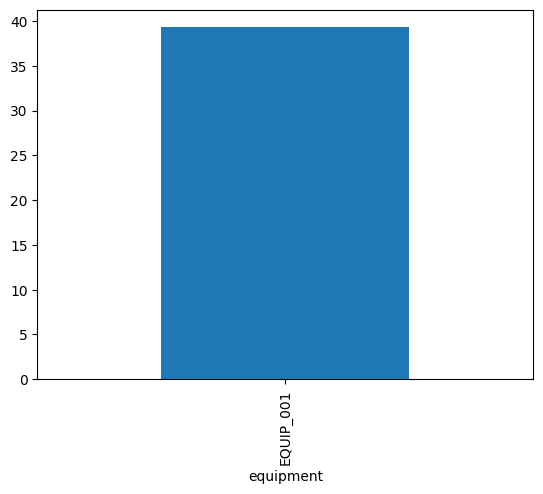

In [ ]:
data.groupby('equipment')['impact_min'].mean().plot(kind='bar')

their is only one equipment in the entire dataset so i can drop this column 

In [ ]:
pd.crosstab(data['failure_category'],data['root_cause_category'])

root_cause_category,Electrical,Idle/External,Logistics/Organization,Mechanical,Other
failure_category,,,,,
Electrical,144,0,0,0,0
Idle/External,0,66,0,0,0
Logistics/Organization,0,0,598,0,0
Mechanical,0,0,0,177,0
Other,0,0,0,0,14


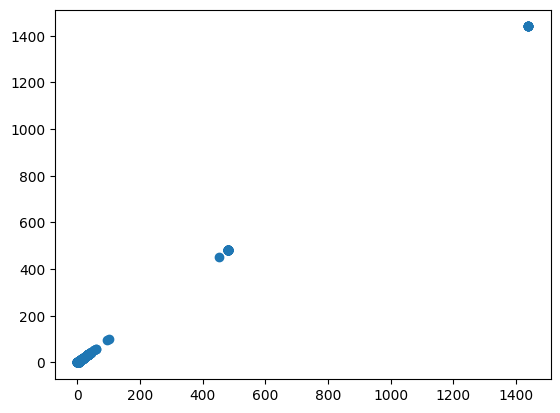

In [ ]:
plt.scatter(x=data['mttr_min'],y=data['impact_min'])

both the impact_min and mttr_min all the values are same 

In [ ]:
data[['impact_min','mttr_min','mtbf_hours']].corr()

,impact_min,mttr_min,mtbf_hours
impact_min,1.000000,1.000000,0.321353
mttr_min,1.000000,1.000000,0.321353
mtbf_hours,0.321353,0.321353,1.000000


<Axes: xlabel='mttr_min'>

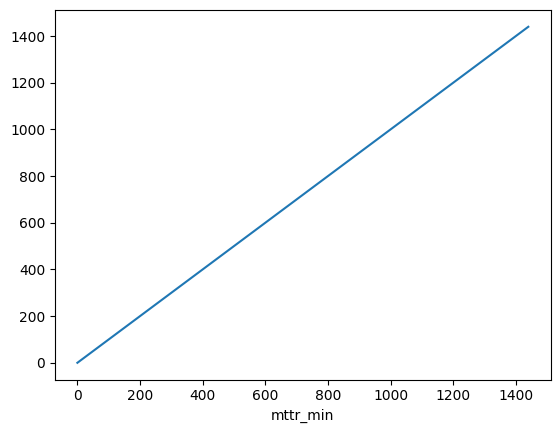

In [ ]:
data.groupby('mttr_min')['impact_min'].mean().plot()

both mttr_min and impact_min time are same so their is a data lekage problem with either of the colunms so i can drop any of the column from training to prevent data lekage 

In [ ]:
data.groupby('failure_category')['impact_min'].mean()

failure_category
Electrical                  5.652500
Idle/External             515.954545
Logistics/Organization      5.817191
Mechanical                  4.554915
Other                       8.502857
Name: impact_min, dtype: float64

In [ ]:
data['mtbf_hours']=data['mtbf_hours'].fillna(data['mtbf_hours'].median())

i had filled the one empty value in mtbf_hours column with median value

In [ ]:
#after handling the missing values the null value count 
data['mtbf_hours'].isnull().sum()

0

Text(0.5, 1.0, 'Boxplot of impact_min column')

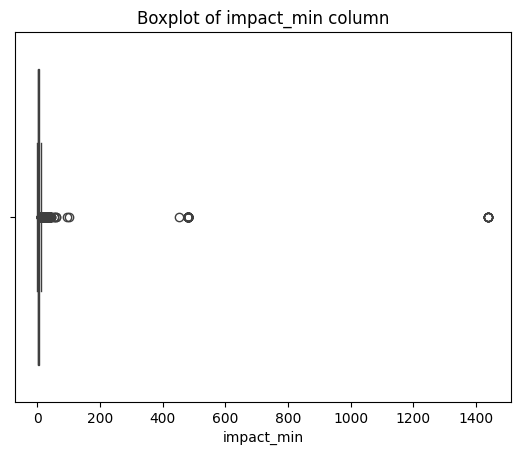

In [ ]:
sns.boxplot(x=data['impact_min'])
plt.title("Boxplot of impact_min column")

All the values in impact_min are concentrated at low range only

In [ ]:
for cutoff in [200, 300, 500]:
    filtered = data[data['impact_min'] <= cutoff]
    dropped = len(data) - len(filtered)
    print(f"\nCutoff = {cutoff}  |  Rows dropped: {dropped}  |  Remaining: {len(filtered)}")
    print(filtered.groupby('failure_category')['impact_min'].agg(['count','mean']))


Cutoff = 200  |  Rows dropped: 55  |  Remaining: 944
                        count      mean
failure_category                       
Electrical                144  5.652500
Idle/External              11  0.000000
Logistics/Organization    598  5.817191
Mechanical                177  4.554915
Other                      14  8.502857

Cutoff = 300  |  Rows dropped: 55  |  Remaining: 944
                        count      mean
failure_category                       
Electrical                144  5.652500
Idle/External              11  0.000000
Logistics/Organization    598  5.817191
Mechanical                177  4.554915
Other                      14  8.502857

Cutoff = 500  |  Rows dropped: 8  |  Remaining: 991
                        count        mean
failure_category                         
Electrical                144    5.652500
Idle/External              58  388.500000
Logistics/Organization    598    5.817191
Mechanical                177    4.554915
Other                      

number of records remaining as per handling the outliers

In [ ]:
data['impact_min'].describe()

count     999.000000
mean       39.310210
std       161.328091
min         0.000000
25%         1.020000
50%         1.980000
75%         4.980000
max      1440.000000
Name: impact_min, dtype: float64

From this the data i can say data is extremely skewed

In [ ]:
data['impact_min'].isnull().sum()

0

In [ ]:
Q1 = data['impact_min'].quantile(0.25)
Q3 = data['impact_min'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper Bound:", upper_bound)

Q1: 1.02
Q3: 4.98
IQR: 3.9600000000000004
Upper Bound: 10.920000000000002


In [ ]:
data.shape

(999, 15)

In [ ]:
data = data[data['impact_min'] <= 500]

In [ ]:
data.shape

(991, 15)

(array([942.,   2.,   0.,   0.,  47.]),
 array([  0.,  96., 192., 288., 384., 480.]),
 <BarContainer object of 5 artists>)

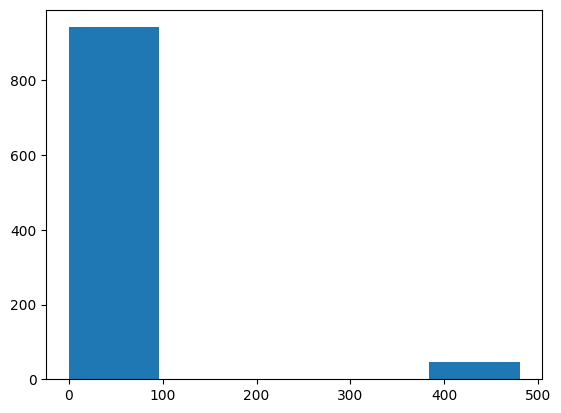

In [ ]:
plt.hist(x=data['impact_min'],bins=5)

In [ ]:
import numpy as np
data['impact_min_log'] = np.log1p(data['impact_min'])

(array([942.,   2.,   0.,   0.,  47.]),
 array([  0.,  96., 192., 288., 384., 480.]),
 <BarContainer object of 5 artists>)

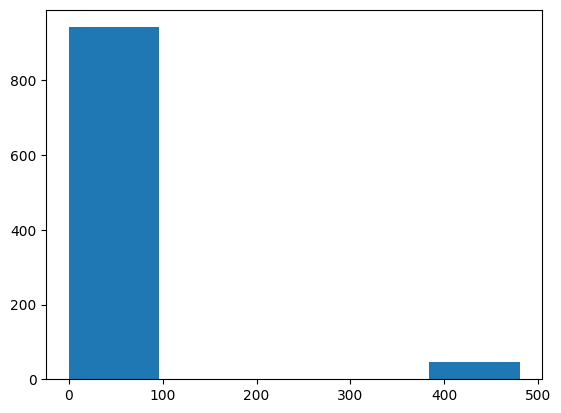

In [ ]:
#before appling log
plt.hist(x=data['impact_min'],bins=5)

(array([ 34., 548., 177.,  68.,  41.,  60.,  14.,   2.,   0.,  47.]),
 array([0.        , 0.61758673, 1.23517345, 1.85276018, 2.47034691,
        3.08793364, 3.70552036, 4.32310709, 4.94069382, 5.55828054,
        6.17586727]),
 <BarContainer object of 10 artists>)

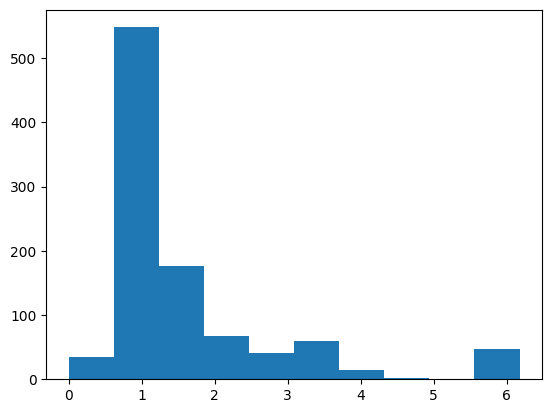

In [ ]:
#after applying log
plt.hist(data['impact_min_log'],bins=10)

In [ ]:
print("skewness before appling log:",data['impact_min'].skew()) 
print("skewness after appling log:",data['impact_min_log'].skew())

#Skewness is reduced after appling log function to impact_min column

skewness before appling log: 4.201518696962355
skewness after appling log: 2.042032277479832


In [ ]:
data.columns

Index(['event_id', 'timestamp', 'region', 'area', 'equipment', 'failure_name',
       'failure_category', 'severity', 'root_cause', 'root_cause_category',
       'impact_min', 'mttr_min', 'mtbf_hours', 'year', 'month',
       'impact_min_log'],
      dtype='object')

In [ ]:
#converting timestmap column into day month year format
data['timestamp']=pd.to_datetime(data['timestamp'],dayfirst=True)

In [ ]:
data['hour'] = data['timestamp'].dt.hour
data['day'] = data['timestamp'].dt.day
data['dayofweek'] = data['timestamp'].dt.dayofweek

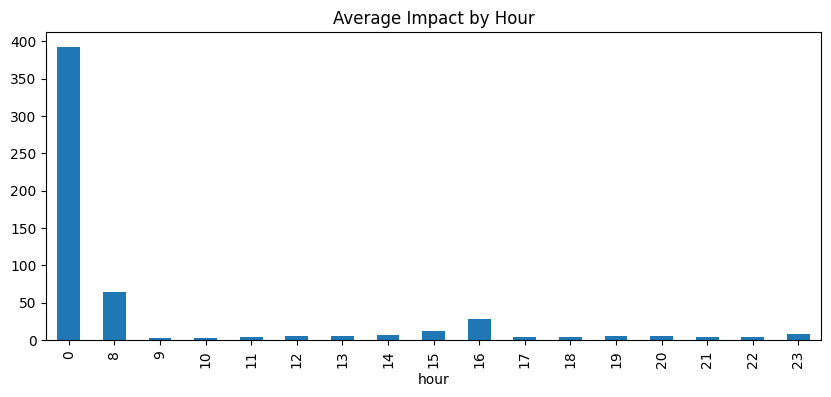

In [ ]:
data.groupby('hour')['impact_min'].mean().plot(kind='bar', figsize=(10,4))
plt.title("Average Impact by Hour")
plt.show()

how hour of the day effort the impact_min column

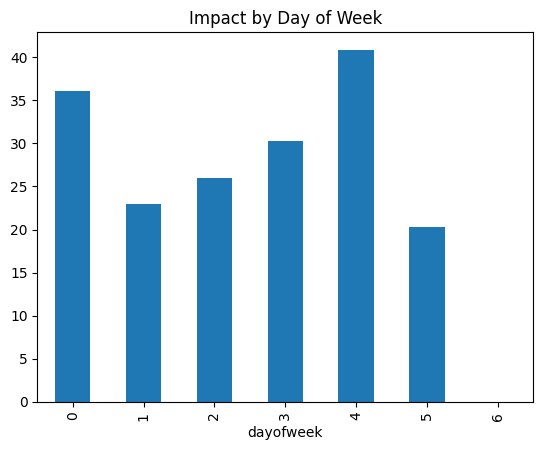

In [ ]:
data.groupby('dayofweek')['impact_min'].mean().plot(kind='bar')
plt.title("Impact by Day of Week")
plt.show()

How dayofweek effort the impact_min column

<Axes: >

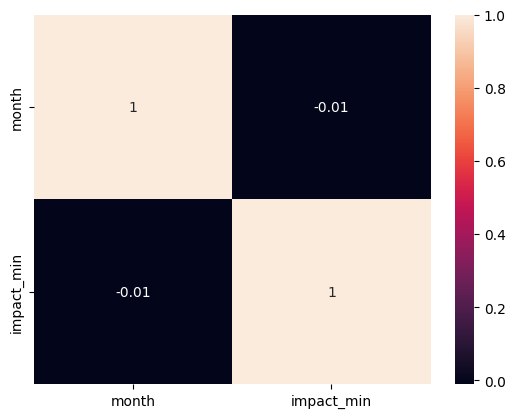

In [ ]:
sns.heatmap(data[['month','impact_min']].corr(),annot=True)

month column has no correlation with impact_min column because it has only 2 months if records

In [ ]:
data.groupby('hour')['impact_min'].mean()

hour
0     392.727273
8      64.481194
9       2.238750
10      2.889310
11      4.152857
12      5.226000
13      4.962973
14      7.208000
15     11.710500
16     28.376571
17      3.472340
18      4.064444
19      5.646667
20      5.629688
21      3.468571
22      4.514694
23      8.246757
Name: impact_min, dtype: float64

In [ ]:
data.groupby('month')['impact_min'].mean()

month
1.0    28.720325
2.0    26.456178
Name: impact_min, dtype: float64

<Axes: >

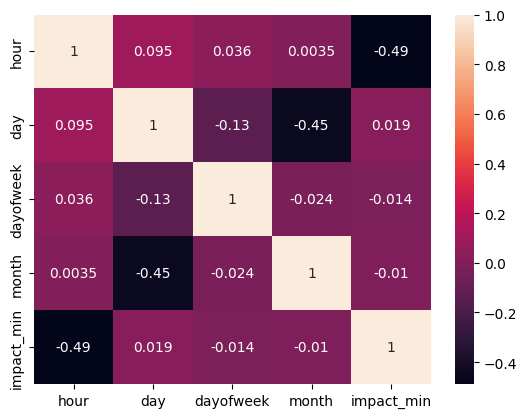

In [ ]:
sns.heatmap(data[['hour','day','dayofweek','month','impact_min']].corr(),annot=True)

how one column is related to each other columns

There is no relation between hour, day, day of week, month so i can drop them 

In [ ]:
data.columns

Index(['event_id', 'timestamp', 'region', 'area', 'equipment', 'failure_name',
       'failure_category', 'severity', 'root_cause', 'root_cause_category',
       'impact_min', 'mttr_min', 'mtbf_hours', 'year', 'month',
       'impact_min_log', 'hour', 'day', 'dayofweek'],
      dtype='object')

<Axes: >

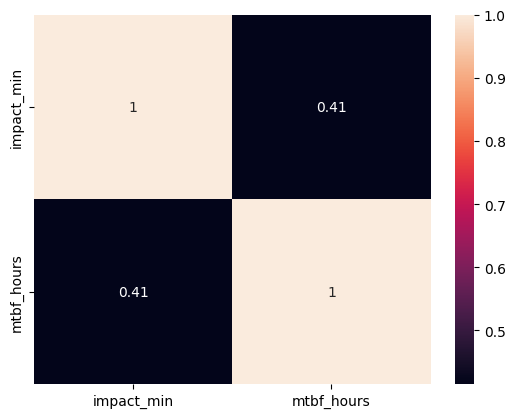

In [ ]:
sns.heatmap(data[['impact_min','mtbf_hours']].corr(),annot=True)

In [ ]:
data = data.drop(columns=[
    'event_id',
    'timestamp',
    'region',
    'area',
    'equipment',
    'root_cause',
    'severity',
    'mttr_min',
    'hour',
    'day',
    'dayofweek',
    'year'   
])

the above columns are dropped

In [ ]:
data.columns

Index(['failure_name', 'failure_category', 'root_cause_category', 'impact_min',
       'mtbf_hours', 'month', 'impact_min_log'],
      dtype='object')

In [ ]:
data = pd.get_dummies(
    data,
    columns=['failure_category', 'root_cause_category'],
    drop_first=True
)

One hot encoding for failure_category and root_cause_category columns

In [ ]:
data.head()

,failure_name,impact_min,mtbf_hours,month,impact_min_log,failure_category_Idle/External,failure_category_Logistics/Organization,failure_category_Mechanical,failure_category_Other,root_cause_category_Idle/External,root_cause_category_Logistics/Organization,root_cause_category_Mechanical,root_cause_category_Other
1,Ajuste apliacdor de sacos,1.02,0.816667,1.0,0.703098,False,False,True,False,False,False,True,False
2,Falta de bolsa en magaz/atoram. atoramie,1.02,0.150000,1.0,0.703098,False,True,False,False,False,True,False,False
3,Falta de bolsa en magaz/atoram. atoramie,1.02,0.150000,1.0,0.703098,False,True,False,False,False,True,False,False
4,Falta de bolsa en magaz/atoram. atoramie,1.02,0.116667,1.0,0.703098,False,True,False,False,False,True,False,False
5,Falta de bolsa en magaz/atoram. atoramie,1.02,0.416667,1.0,0.703098,False,True,False,False,False,True,False,False


In [ ]:
data.columns

Index(['failure_name', 'impact_min', 'mtbf_hours', 'month', 'impact_min_log',
       'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other',
       'root_cause_category_Idle/External',
       'root_cause_category_Logistics/Organization',
       'root_cause_category_Mechanical', 'root_cause_category_Other'],
      dtype='object')

In [ ]:
data=data.drop('impact_min',axis=1)

In [ ]:
data.columns

Index(['failure_name', 'mtbf_hours', 'month', 'impact_min_log',
       'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other',
       'root_cause_category_Idle/External',
       'root_cause_category_Logistics/Organization',
       'root_cause_category_Mechanical', 'root_cause_category_Other'],
      dtype='object')

In [ ]:
data.shape

(991, 12)

In [ ]:
data['failure_category_Idle/External'][1]

False

In [ ]:
(data['failure_category'] == data['root_cause_category']).all()

In [ ]:
(data['failure_category_Mechanical'] == data['root_cause_category_Mechanical']).all()

True

Both the Failure_category and root_cause_category are same so their is a possible of data lekage so i can drop any one of them

In [ ]:
data = data.drop(columns=[
    'root_cause_category_Idle/External',
    'root_cause_category_Logistics/Organization',
    'root_cause_category_Mechanical',
    'root_cause_category_Other'
])
data.columns

Index(['failure_name', 'mtbf_hours', 'month', 'impact_min_log',
       'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other'],
      dtype='object')

I had dropped the root_cause_category column

In [ ]:
data.head()

,failure_name,mtbf_hours,month,impact_min_log,failure_category_Idle/External,failure_category_Logistics/Organization,failure_category_Mechanical,failure_category_Other
1,Ajuste apliacdor de sacos,0.816667,1.0,0.703098,False,False,True,False
2,Falta de bolsa en magaz/atoram. atoramie,0.150000,1.0,0.703098,False,True,False,False
3,Falta de bolsa en magaz/atoram. atoramie,0.150000,1.0,0.703098,False,True,False,False
4,Falta de bolsa en magaz/atoram. atoramie,0.116667,1.0,0.703098,False,True,False,False
5,Falta de bolsa en magaz/atoram. atoramie,0.416667,1.0,0.703098,False,True,False,False


In [ ]:
print(data.columns)
data.shape

Index(['failure_name', 'mtbf_hours', 'month', 'impact_min_log',
       'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other'],
      dtype='object')


(991, 8)

In [ ]:
x = data.drop(['impact_min_log'], axis=1)
y = data['impact_min_log']

spliting the feature and target columns

In [ ]:
x.columns

Index(['failure_name', 'mtbf_hours', 'month', 'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other'],
      dtype='object')

In [ ]:
x.head()

,failure_name,mtbf_hours,month,failure_category_Idle/External,failure_category_Logistics/Organization,failure_category_Mechanical,failure_category_Other
1,Ajuste apliacdor de sacos,0.816667,1.0,False,False,True,False
2,Falta de bolsa en magaz/atoram. atoramie,0.150000,1.0,False,True,False,False
3,Falta de bolsa en magaz/atoram. atoramie,0.150000,1.0,False,True,False,False
4,Falta de bolsa en magaz/atoram. atoramie,0.116667,1.0,False,True,False,False
5,Falta de bolsa en magaz/atoram. atoramie,0.416667,1.0,False,True,False,False


In [ ]:
y.head()

1    0.703098
2    0.703098
3    0.703098
4    0.703098
5    0.703098
Name: impact_min_log, dtype: float64

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

splitting x and y into testing and training data

In [ ]:
x_train.shape

(792, 7)

In [ ]:
x_test.shape

(199, 7)

In [ ]:
# combine train + target
train_data = x_train.copy()
train_data['impact_min_log'] = y_train

# compute mean per failure_name
name_mean = train_data.groupby('failure_name')['impact_min_log'].mean()
print(name_mean)
# apply mapping
x_train['failure_name_enc'] = x_train['failure_name'].map(name_mean)
x_test['failure_name_enc'] = x_test['failure_name'].map(name_mean)

# handle unseen values
global_mean = y_train.mean()
x_test['failure_name_enc'] = x_test['failure_name_enc'].fillna(global_mean)

# drop original column
x_train = x_train.drop(columns=['failure_name'])
x_test = x_test.drop(columns=['failure_name'])

failure_name
 atoramIENTO DE SACOS EN APLICADOR          0.703098
2010 Fallo de equipo                        0.703098
2010 Fallo de equipo Se daña varilla de     2.996732
2010 Fallo de equipo curva rodillos 671     3.638112
2010 Fallo de equipo falla de diafragma     0.814191
                                              ...   
montacargas electricos en proceso de apr    0.897510
personal en capacitación                    0.800304
personal en entrenamiento                   0.930681
solo 1 operador en línea por horario de     1.009390
valvula de 11 cm                            2.393473
Name: impact_min_log, Length: 131, dtype: float64


the failure_name column is encoded with the target encoding with target column mean of its category

In [ ]:
y_train.shape

(792,)

common code to evaluate the differnt models

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(model, X_train, X_test, y_train, y_test, name):
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    
    # convert back to actual
    y_test_actual = np.expm1(y_test)
    y_pred_actual = np.expm1(y_pred)
    
    mae = mean_absolute_error(y_test_actual, y_pred_actual)
    rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
    r2 = r2_score(y_test_actual, y_pred_actual)
    
    print(f"{name}")
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2:", r2)
    print("-"*40)
    
    return mae, rmse, r2

**Linear Regression**

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
evaluate_model(lr, x_train, x_test, y_train, y_test, "Linear Regression")

Linear Regression
MAE: 21.973177158264296
RMSE: 77.27375050144325
R2: 0.5359949229597096
----------------------------------------


(21.973177158264296, 77.27375050144325, 0.5359949229597096)

**Decision Tress**

In [ ]:
from sklearn.tree import DecisionTreeRegressor

for depth in [3, 5, 10]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
    evaluate_model(dt, x_train, x_test, y_train, y_test, f"Decision Tree depth={depth}")

Decision Tree depth=3
MAE: 12.624999799183174
RMSE: 49.09424906608673
R2: 0.8127076698146595
----------------------------------------
Decision Tree depth=5
MAE: 10.330409032479405
RMSE: 54.85423497384719
R2: 0.7661813897289241
----------------------------------------
Decision Tree depth=10
MAE: 11.012778489460159
RMSE: 59.83203070779176
R2: 0.7218197865338172
----------------------------------------


**Random Forest Regressor**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

for n in [100, 200, 300]:
    for depth in [5, 10]:
        rf = RandomForestRegressor(
            n_estimators=n,
            max_depth=depth,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42
        )
        evaluate_model(rf, x_train, x_test, y_train, y_test,
                       f"RF n={n}, depth={depth}")

RF n=100, depth=5
MAE: 12.047305425772226
RMSE: 55.52991677326021
R2: 0.7603856657355296
----------------------------------------
RF n=100, depth=10
MAE: 12.574836875562971
RMSE: 57.29768824813049
R2: 0.7448867883996815
----------------------------------------
RF n=200, depth=5
MAE: 12.749343693190749
RMSE: 57.45678578263194
R2: 0.7434680842922164
----------------------------------------
RF n=200, depth=10
MAE: 13.083285886025797
RMSE: 58.68953232472601
R2: 0.7323421115955887
----------------------------------------
RF n=300, depth=5
MAE: 12.523035500484559
RMSE: 56.97290999136025
R2: 0.7477706884014866
----------------------------------------
RF n=300, depth=10
MAE: 12.89267261959054
RMSE: 58.35602647787172
R2: 0.7353754240018517
----------------------------------------


**Gradinet Boosting Regressor**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

for lr_rate in [0.05, 0.1]:
    gb = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=lr_rate,
        max_depth=3
    )
    evaluate_model(gb, x_train, x_test, y_train, y_test,
                   f"GB lr={lr_rate}")

GB lr=0.05
MAE: 15.085052948661117
RMSE: 65.79316559302202
R2: 0.6636276299740602
----------------------------------------
GB lr=0.1
MAE: 15.66911659394159
RMSE: 67.58275684434446
R2: 0.6450799312087927
----------------------------------------


**KNN**

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

for k in [3, 5, 7]:
    knn = KNeighborsRegressor(n_neighbors=k)
    evaluate_model(knn, x_train, x_test, y_train, y_test,
                   f"KNN k={k}")

KNN k=3
MAE: 11.125911668121006
RMSE: 55.3460635704169
R2: 0.7619697103985489
----------------------------------------
KNN k=5
MAE: 10.687465812738933
RMSE: 53.36995706388906
R2: 0.7786637963564584
----------------------------------------
KNN k=7
MAE: 15.210055472130142
RMSE: 65.04304158284994
R2: 0.6712540331761387
----------------------------------------


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
import numpy as np

**Decision Tree Regressor With Cross validation**

In [ ]:
dt = DecisionTreeRegressor(max_depth=5, random_state=42)

scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

scores = cross_validate(
    dt,
    x_train,
    y_train,
    scoring=scoring,
    cv=5,
    return_train_score=False
)

# convert values
mae = -scores['test_mae']
rmse = -scores['test_rmse']
r2 = scores['test_r2']

print("Decision Tree Results:")
print("MAE:", mae)
print("Avg MAE:", np.mean(mae))
print("RMSE:", rmse)
print("Avg RMSE:", np.mean(rmse))
print("R2:", r2)
print("Avg R2:", np.mean(r2))

Decision Tree Results:
MAE: [0.39263791 0.43543406 0.41394069 0.5084438  0.40893952]
Avg MAE: 0.4318791940280822
RMSE: [0.58118924 0.64553846 0.64242871 0.82778349 0.60096244]
Avg RMSE: 0.6595804691283916
R2: [0.78308261 0.76693699 0.77264419 0.64295335 0.78556267]
Avg R2: 0.7502359617880393


**Random Forerst with cross validation**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42)

scores = cross_validate(
    rf,
    x_train,
    y_train,
    scoring=scoring,
    cv=5
)

mae = -scores['test_mae']
rmse = -scores['test_rmse']
r2 = scores['test_r2']

print("Random Forest Avg MAE:", np.mean(mae))
print("Random Forest Avg RMSE:", np.mean(rmse))
print("Random Forest Avg R2:", np.mean(r2))

Random Forest Avg MAE: 0.45901340534754115
Random Forest Avg RMSE: 0.6924703524658733
Random Forest Avg R2: 0.7220979260271995


**KNN with cross validation**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5))
])

scores = cross_validate(
    knn_pipeline,
    x_train,
    y_train,
    scoring=scoring,
    cv=5
)

mae = -scores['test_mae']
rmse = -scores['test_rmse']
r2 = scores['test_r2']

print("KNN Avg MAE:", np.mean(mae))
print("KNN Avg RMSE:", np.mean(rmse))
print("KNN Avg R2:", np.mean(r2))

KNN Avg MAE: 0.5415402433739351
KNN Avg RMSE: 0.8605703352941966
KNN Avg R2: 0.5696632636406982


Voting Regressor is a wrapper that combines predictions from several models-(here random forest and gradient boosting regression algorithms) by averaging them

Common code for metric evaluation with both actual and logrithmic values

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
def evaluate(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    preds_log = model.predict(X_test)
    
    # metrics on log scale (what the model was trained/optimized on)
    r2_log = r2_score(y_test, preds_log)
    mae_log = mean_absolute_error(y_test, preds_log)
    rmse_log = np.sqrt(mean_squared_error(y_test, preds_log))
    
    # convert both predictions and actuals back to real minutes
    preds_actual = np.expm1(preds_log)
    y_test_actual = np.expm1(y_test)
    
    # metrics on original scale (what actually matters for interpretation)
    r2_actual = r2_score(y_test_actual, preds_actual)
    mae_actual = mean_absolute_error(y_test_actual, preds_actual)
    rmse_actual = np.sqrt(mean_squared_error(y_test_actual, preds_actual))
    
    print(f"{name}")
    print(f"  [log scale]      R2: {r2_log:.4f}  MAE: {mae_log:.4f}  RMSE: {rmse_log:.4f}")
    print(f"  [minutes scale]  R2: {r2_actual:.4f}  MAE: {mae_actual:.2f} min  RMSE: {rmse_actual:.2f} min")
    print()
    
    return {
        "Model": name,
        "R2_log": r2_log, "MAE_log": mae_log, "RMSE_log": rmse_log,
        "R2_actual": r2_actual, "MAE_actual": mae_actual, "RMSE_actual": rmse_actual
    }

**Hyperparameter tunnning for various models**

**Linear regression**

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
res_lr = evaluate("Linear Regression", lr, x_train, y_train, x_test, y_test)

Linear Regression
  [log scale]      R2: 0.5508  MAE: 0.6288  RMSE: 0.9852
  [minutes scale]  R2: 0.5360  MAE: 21.97 min  RMSE: 77.27 min



In [ ]:
from sklearn.linear_model import Ridge

ridge_alpha =1   # try: 0.01, 0.1, 1, 10, 100

ridge = Ridge(alpha=ridge_alpha)
res_ridge = evaluate(f"Ridge (alpha={ridge_alpha})", ridge, x_train, y_train, x_test, y_test)

Ridge (alpha=1)
  [log scale]      R2: 0.5511  MAE: 0.6289  RMSE: 0.9849
  [minutes scale]  R2: 0.5363  MAE: 21.95 min  RMSE: 77.25 min



**Gradient Boosting Regressor hyperparameter tunning**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_n_estimators = 500     # try: 50, 100, 200, 500
gb_max_depth = 3          # try: 2, 3, 4, 5
gb_learning_rate = 0.1    # try: 0.01, 0.05, 0.1, 0.3

gb = GradientBoostingRegressor(
    n_estimators=gb_n_estimators,
    max_depth=gb_max_depth,
    learning_rate=gb_learning_rate,
    random_state=42
)
res_gb = evaluate(f"Gradient Boosting (n={gb_n_estimators}, depth={gb_max_depth}, lr={gb_learning_rate})",
                   gb, x_train, y_train, x_test, y_test)

Gradient Boosting (n=500, depth=3, lr=0.1)
  [log scale]      R2: 0.3122  MAE: 0.6763  RMSE: 1.2191
  [minutes scale]  R2: 0.6220  MAE: 16.86 min  RMSE: 69.74 min



In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_n_estimators = 200     # try: 50, 100, 200, 500
gb_max_depth = 3          # try: 2, 3, 4, 5
gb_learning_rate = 0.1    # try: 0.01, 0.05, 0.1, 0.3

gb = GradientBoostingRegressor(
    n_estimators=gb_n_estimators,
    max_depth=gb_max_depth,
    learning_rate=gb_learning_rate,
    random_state=42
)
res_gb = evaluate(f"Gradient Boosting (n={gb_n_estimators}, depth={gb_max_depth}, lr={gb_learning_rate})",
                   gb, x_train, y_train, x_test, y_test)

Gradient Boosting (n=200, depth=3, lr=0.1)
  [log scale]      R2: 0.3808  MAE: 0.6454  RMSE: 1.1568
  [minutes scale]  R2: 0.6448  MAE: 15.68 min  RMSE: 67.61 min



**Random Forest Regressor hyperparameter tunning**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_n_estimators = 500
rf_max_depth = 10
rf_min_samples_leaf = 5

rf = RandomForestRegressor(
    n_estimators=rf_n_estimators,
    max_depth=rf_max_depth,
    min_samples_leaf=rf_min_samples_leaf,
    random_state=42
)
res_rf = evaluate(f"RF (n={rf_n_estimators}, depth={rf_max_depth}, leaf={rf_min_samples_leaf})",
                   rf, x_train, y_train, x_test, y_test)

RF (n=500, depth=10, leaf=5)
  [log scale]      R2: 0.5744  MAE: 0.5756  RMSE: 0.9590
  [minutes scale]  R2: 0.7629  MAE: 12.92 min  RMSE: 55.24 min



**SVM hypermeter tunning**

In [ ]:
from sklearn.svm import SVR

svr_C = 1.0           # try: 0.1, 1, 10, 100
svr_epsilon = 0.1     # try: 0.01, 0.1, 0.5
svr_kernel = 'rbf'    # try: 'linear', 'rbf', 'poly'

svr = SVR(C=svr_C, epsilon=svr_epsilon, kernel=svr_kernel)
res_svr = evaluate(f"SVR (C={svr_C}, eps={svr_epsilon}, kernel={svr_kernel})",
                    svr, x_train, y_train, x_test, y_test)

SVR (C=1.0, eps=0.1, kernel=rbf)
  [log scale]      R2: 0.5556  MAE: 0.5814  RMSE: 0.9800
  [minutes scale]  R2: 0.8051  MAE: 12.88 min  RMSE: 50.08 min



In [ ]:
from sklearn.svm import SVR

svr_C = 10           # try: 0.1, 1, 10, 100
svr_epsilon = 0.01     # try: 0.01, 0.1, 0.5
svr_kernel = 'rbf'    # try: 'linear', 'rbf', 'poly'

svr = SVR(C=svr_C, epsilon=svr_epsilon, kernel=svr_kernel)
res_svr = evaluate(f"SVR (C={svr_C}, eps={svr_epsilon}, kernel={svr_kernel})",
                    svr, x_train, y_train, x_test, y_test)

SVR (C=10, eps=0.01, kernel=rbf)
  [log scale]      R2: 0.5751  MAE: 0.5597  RMSE: 0.9582
  [minutes scale]  R2: 0.8493  MAE: 8.86 min  RMSE: 44.04 min



**Hist Gradient Boosting hyperparameter Tunning**

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
res_hgb = evaluate("HistGradientBoosting (iter=200, depth=5, lr=0.1)", hgb, x_train, y_train, x_test, y_test)

HistGradientBoosting (iter=200, depth=5, lr=0.1)
  [log scale]      R2: 0.5828  MAE: 0.5731  RMSE: 0.9495
  [minutes scale]  R2: 0.6614  MAE: 15.77 min  RMSE: 66.01 min



In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(
    max_iter=200,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
res_hgb = evaluate("HistGradientBoosting (iter=200, depth=5, lr=0.1)", hgb, x_train, y_train, x_test, y_test)

HistGradientBoosting (iter=200, depth=5, lr=0.1)
  [log scale]      R2: 0.5828  MAE: 0.5731  RMSE: 0.9495
  [minutes scale]  R2: 0.6614  MAE: 15.77 min  RMSE: 66.01 min



In [ ]:
x_train.head()

,mtbf_hours,month,failure_category_Idle/External,failure_category_Logistics/Organization,failure_category_Mechanical,failure_category_Other,failure_name_enc
217,0.066667,1.0,False,True,False,False,1.094942
297,0.400000,1.0,False,True,False,False,1.990592
50,0.533333,1.0,False,True,False,False,1.462006
727,0.700000,2.0,False,True,False,False,1.141902
237,0.333333,1.0,False,False,False,False,1.214178


In [ ]:
x_combined = pd.concat([x_train, x_test]).sort_index()
y_combined = pd.concat([y_train, y_test]).sort_index()

print(x_combined.shape, y_combined.shape)
x_combined.columns

(991, 7) (991,)


Index(['mtbf_hours', 'month', 'failure_category_Idle/External',
       'failure_category_Logistics/Organization',
       'failure_category_Mechanical', 'failure_category_Other',
       'failure_name_enc'],
      dtype='object')

**Using Cross validation for different models for comparision**

In [ ]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
import numpy as np
import pandas as pd

# recombine train/test (already has failure_name_enc instead of raw failure_name)
x_combined = pd.concat([x_train, x_test]).sort_index()
y_combined = pd.concat([y_train, y_test]).sort_index()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_cv(name, model, x, y):
    preds_log_cv = cross_val_predict(model, x, y, cv=kf)
    preds_actual = np.expm1(preds_log_cv)
    y_actual = np.expm1(y)
    r2 = r2_score(y_actual, preds_actual)
    mae = mean_absolute_error(y_actual, preds_actual)
    rmse = np.sqrt(mean_squared_error(y_actual, preds_actual))
    print(f"{name:40s}  R2={r2:.4f}  MAE={mae:6.2f} min  RMSE={rmse:6.2f} min")
    return {"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse}

results = []

results.append(evaluate_cv("Linear Regression", LinearRegression(), x_combined, y_combined))
results.append(evaluate_cv("Ridge (alpha=1)", Ridge(alpha=1), x_combined, y_combined))
results.append(evaluate_cv("Random Forest (n=300, depth=None, leaf=1)",
    RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=1, random_state=42), x_combined, y_combined))
results.append(evaluate_cv("Gradient Boosting (n=200, depth=2, lr=0.05)",
    GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, random_state=42), x_combined, y_combined))
results.append(evaluate_cv("AdaBoost (n=100, lr=0.1)",
    AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42), x_combined, y_combined))

comparison_df = pd.DataFrame(results)
comparison_df.sort_values("R2", ascending=False)

Linear Regression                         R2=0.5763  MAE= 17.20 min  RMSE= 65.88 min
Ridge (alpha=1)                           R2=0.5756  MAE= 17.21 min  RMSE= 65.93 min
Random Forest (n=300, depth=None, leaf=1)  R2=0.8577  MAE=  7.26 min  RMSE= 38.19 min
Gradient Boosting (n=200, depth=2, lr=0.05)  R2=0.8320  MAE=  9.86 min  RMSE= 41.48 min
AdaBoost (n=100, lr=0.1)                  R2=0.4431  MAE= 19.30 min  RMSE= 75.54 min


,Model,R2,MAE,RMSE
2,"Random Forest (n=300, depth=None, leaf=1)",0.857655,7.263018,38.187530
3,"Gradient Boosting (n=200, depth=2, lr=0.05)",0.832019,9.862579,41.484041
0,Linear Regression,0.576330,17.203124,65.881601
1,Ridge (alpha=1),0.575648,17.205955,65.934629
4,"AdaBoost (n=100, lr=0.1)",0.443063,19.301699,75.535948


**Gridsearch and Cross Validation for different models**

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def grid_search_and_eval(name, model, param_grid, x, y):
    grid = GridSearchCV(model, param_grid, cv=kf, scoring='r2', n_jobs=-1)
    grid.fit(x, y)

    best_model = model.__class__(**grid.best_params_, random_state=42) \
        if 'random_state' in model.get_params() else model.__class__(**grid.best_params_)

    preds_log_cv = cross_val_predict(best_model, x, y, cv=kf)
    preds_actual = np.expm1(preds_log_cv)
    y_actual = np.expm1(y)

    r2 = r2_score(y_actual, preds_actual)
    mae = mean_absolute_error(y_actual, preds_actual)
    rmse = np.sqrt(mean_squared_error(y_actual, preds_actual))

    print(f"{name}")
    print(f"  Best params: {grid.best_params_}")
    print(f"  [minutes] R2: {r2:.4f}  MAE: {mae:.2f} min  RMSE: {rmse:.2f} min\n")

    return {"Model": name, "Best Params": grid.best_params_, "R2": r2, "MAE": mae, "RMSE": rmse}

results = []

# Ridge — Linear Regression has no hyperparameters to tune, so it's skipped here (kept in your plain CV table instead)
results.append(grid_search_and_eval(
    "Ridge", Ridge(),
    {'alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
    x_combined, y_combined
))

results.append(grid_search_and_eval(
    "Random Forest", RandomForestRegressor(random_state=42),
    {'n_estimators': [200, 300, 500], 'max_depth': [8, 10, 12, None], 'min_samples_leaf': [1, 2, 5]},
    x_combined, y_combined
))

results.append(grid_search_and_eval(
    "Gradient Boosting", GradientBoostingRegressor(random_state=42),
    {'n_estimators': [100, 200, 300], 'max_depth': [2, 3, 4], 'learning_rate': [0.01, 0.05, 0.1]},
    x_combined, y_combined
))

results.append(grid_search_and_eval(
    "AdaBoost", AdaBoostRegressor(random_state=42),
    {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 1]},
    x_combined, y_combined
))

comparison_df = pd.DataFrame(results)
comparison_df.sort_values("R2", ascending=False)

Ridge
  Best params: {'alpha': 10}
  [minutes] R2: 0.5688  MAE: 17.24 min  RMSE: 66.47 min

Random Forest
  Best params: {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 200}
  [minutes] R2: 0.8584  MAE: 7.05 min  RMSE: 38.08 min

Gradient Boosting
  Best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100}
  [minutes] R2: 0.7899  MAE: 11.95 min  RMSE: 46.39 min

AdaBoost
  Best params: {'learning_rate': 0.01, 'n_estimators': 50}
  [minutes] R2: 0.8225  MAE: 11.43 min  RMSE: 42.65 min



,Model,Best Params,R2,MAE,RMSE
1,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 1, 'n_est...",0.858423,7.052564,38.084340
3,AdaBoost,"{'learning_rate': 0.01, 'n_estimators': 50}",0.822452,11.431881,42.648939
2,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.789898,11.952582,46.394407
0,Ridge,{'alpha': 10},0.568792,17.244298,66.465146


from this i can say that random forest model is better model by comparing R2, MAE AND RMSE values 

**fitting the randomforestRegressos model as it is a better model so far**

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

# train final model using your GridSearch-winning params, on ALL data (train+test combined)
final_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=1,
    random_state=42
)
final_model.fit(x_combined, y_combined)

print("Feature columns (order matters):", list(x_combined.columns))

Feature columns (order matters): ['mtbf_hours', 'month', 'failure_category_Idle/External', 'failure_category_Logistics/Organization', 'failure_category_Mechanical', 'failure_category_Other', 'failure_name_enc']


**Validation using user values**

In [ ]:
def predict_impact(model, failure_category, mtbf_hours, month, failure_name=None):
    """
    failure_category: one of 'Electrical', 'Idle/External',
                       'Logistics/Organization', 'Mechanical', 'Other'
    mtbf_hours: float
    month: int (1 or 2, based on your data)
    failure_name: optional string; if not seen during training, falls back to the global average
    """
    input_dict = {c: 0 for c in x_combined.columns}
    input_dict['mtbf_hours'] = mtbf_hours
    input_dict['month'] = month

    dummy_col = f'failure_category_{failure_category}'
    if dummy_col in input_dict:
        input_dict[dummy_col] = 1
    elif failure_category != 'Electrical':
        raise ValueError(
            f"Unknown category: {failure_category}. "
            f"Choose from: Electrical, Idle/External, Logistics/Organization, Mechanical, Other"
        )

    # encode failure_name using the same mapping built in cell 97 (name_mean), fallback to global_mean
    if failure_name in name_mean.index:
        input_dict['failure_name_enc'] = name_mean[failure_name]
    else:
        input_dict['failure_name_enc'] = global_mean

    input_df = pd.DataFrame([input_dict])[x_combined.columns]
    pred_log = model.predict(input_df)[0]
    return round(np.expm1(pred_log), 2)

**Sample values for testing**

In [ ]:
samples = [
    ("Idle/External", 1.0, 1, "Turno No laborado"),          
    ("Idle/External", 0.5, 2, None),                         
    ("Mechanical", 0.15, 1, "2010 Fallo de equipo curva rodillos 671"),  
    ("Electrical", 0.3, 1, None),                             
    ("Logistics/Organization", 0.8, 2, "Cambio de presentacion cpc30 42.60 kg a"),  
    ("Other", 0.2, 2, None),                                
]

for cat, mtbf, month, name in samples:
    result = predict_impact(final_model, cat, mtbf, month, name)
    print(f"{cat:25s} mtbf={mtbf:5.2f} month={month}  name={str(name)[:30]:30s} -> {result} min")

Idle/External             mtbf= 1.00 month=1  name=Turno No laborado              -> 10.03 min
Idle/External             mtbf= 0.50 month=2  name=None                           -> 14.85 min
Mechanical                mtbf= 0.15 month=1  name=2010 Fallo de equipo curva rod -> 36.84 min
Electrical                mtbf= 0.30 month=1  name=None                           -> 18.21 min
Logistics/Organization    mtbf= 0.80 month=2  name=Cambio de presentacion cpc30 4 -> 61.04 min
Other                     mtbf= 0.20 month=2  name=None                           -> 21.64 min


**Taking values from user for validation**

In [ ]:
print("Available categories: Electrical, Idle/External, Logistics/Organization, Mechanical, Other")

cat_input = input("Enter failure category: ").strip()
mtbf_input = float(input("Enter mtbf_hours: ").strip())
month_input = int(input("Enter month (1 or 2): ").strip())
name_input = input("Enter failure name (or leave blank if unknown): ").strip()
name_input = name_input if name_input else None

predicted = predict_impact(final_model, cat_input, mtbf_input, month_input, name_input)
print(f"\nPredicted impact_min: {predicted} minutes")

Available categories: Electrical, Idle/External, Logistics/Organization, Mechanical, Other

Predicted impact_min: 8.49 minutes


**Saving model and mean pkl files**

In [ ]:
import joblib

joblib.dump(final_model, "model.pkl")
joblib.dump(name_mean, "name_mean.pkl")   # for encoding
joblib.dump(global_mean, "global_mean.pkl")

['global_mean.pkl']

**Training metrics**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# predictions (log scale)
y_pred_log = final_model.predict(x_combined)

# convert to actual values
y_actual = np.expm1(y_combined)
y_pred_actual = np.expm1(y_pred_log)

print("TRAINING METRICS (on full data)")
print("MAE:", mean_absolute_error(y_actual, y_pred_actual))
print("RMSE:", np.sqrt(mean_squared_error(y_actual, y_pred_actual)))
print("R2:", r2_score(y_actual, y_pred_actual))

TRAINING METRICS (on full data)
MAE: 4.395878760683508
RMSE: 26.07711118688021
R2: 0.9336229581933555


**Training metrics**

In [ ]:
# predictions
y_test_pred_log = final_model.predict(x_test)

# convert back to actual values from log
y_test_actual = np.expm1(y_test)
y_test_pred_actual = np.expm1(y_test_pred_log)

print("\nTEST METRICS")
print("MAE:", mean_absolute_error(y_test_actual, y_test_pred_actual))
print("RMSE:", np.sqrt(mean_squared_error(y_test_actual, y_test_pred_actual)))
print("R2:", r2_score(y_test_actual, y_test_pred_actual))


TEST METRICS
MAE: 9.418993434461848
RMSE: 49.34025512882535
R2: 0.8108259631710453
